Import libraries and load the dataset

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Project location
project = Path.cwd().parent

# Load dataset
df = pd.read_csv(
    project / "Data-raw" / "Telco-Customer-Churn-Cleaned.csv"
)

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


InternetService Analysis

In [9]:
print(df["InternetService"].value_counts())

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64


Visualize InternetService

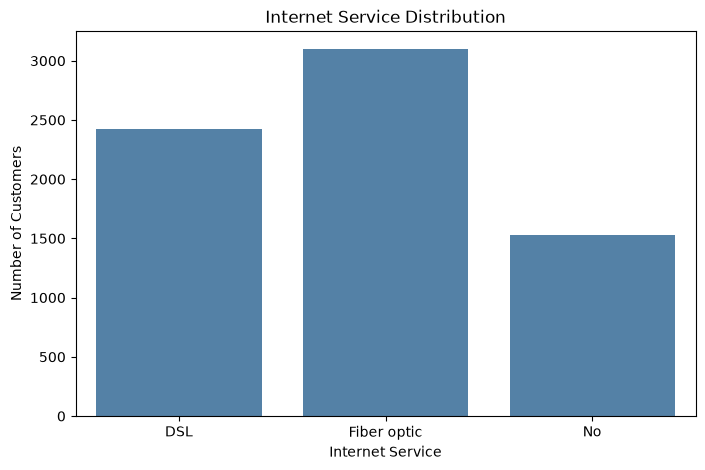

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="InternetService",
    color="steelblue"
)

plt.title("Internet Service Distribution")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

Calculate churn rate by InternetService

In [11]:
internet_churn = (
    df.groupby("InternetService")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

display(internet_churn.round(2))

InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Churn, dtype: float64

Visualize internet churn rates

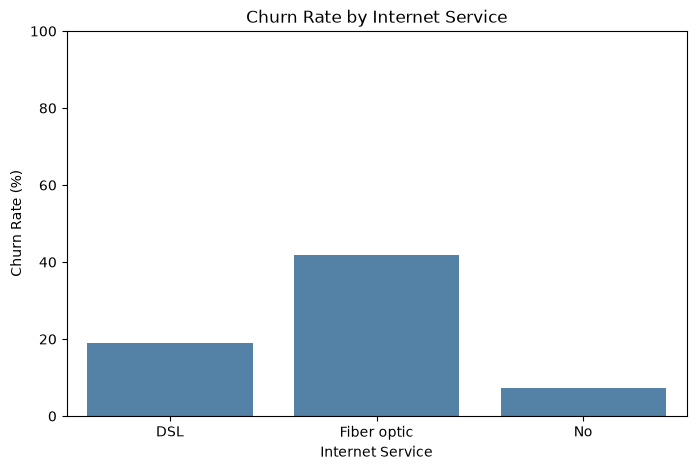

In [12]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=internet_churn.index,
    y=internet_churn.values,
    color="steelblue"
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

plt.show()

OnlineSecurity Analysis

In [13]:
print(df["OnlineSecurity"].value_counts())

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64


Calculate churn rate

In [14]:
security_churn = (
    df.groupby("OnlineSecurity")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

display(security_churn.round(2))

OnlineSecurity
No                     41.77
No internet service     7.40
Yes                    14.61
Name: Churn, dtype: float64

Visualize churn rate

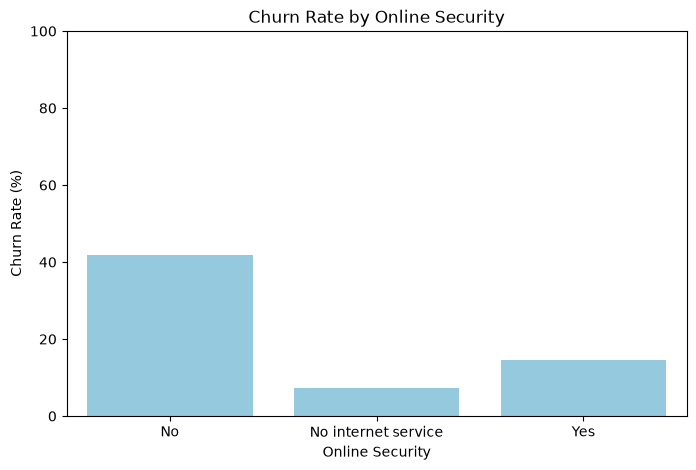

In [15]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=security_churn.index,
    y=security_churn.values,
    color="skyblue"
)

plt.title("Churn Rate by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

plt.show()

Analyze all six additional services

In [16]:
service_features = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

Calculate churn rates

In [17]:
for feature in service_features:

    churn_rate = (
        df.groupby(feature)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    print(f"\nChurn Rate by {feature}")

    display(churn_rate.round(2))


Churn Rate by OnlineSecurity


OnlineSecurity
No                     41.77
Yes                    14.61
No internet service     7.40
Name: Churn, dtype: float64


Churn Rate by OnlineBackup


OnlineBackup
No                     39.93
Yes                    21.53
No internet service     7.40
Name: Churn, dtype: float64


Churn Rate by DeviceProtection


...

TechSupport
No                     41.64
Yes                    15.17
No internet service     7.40
Name: Churn, dtype: float64


Churn Rate by StreamingTV


StreamingTV
No                     33.52
Yes                    30.07
No internet service     7.40
Name: Churn, dtype: float64


Churn Rate by StreamingMovies


StreamingMovies
No                     33.68
Yes                    29.94
No internet service     7.40
Name: Churn, dtype: float64

Create six graphs

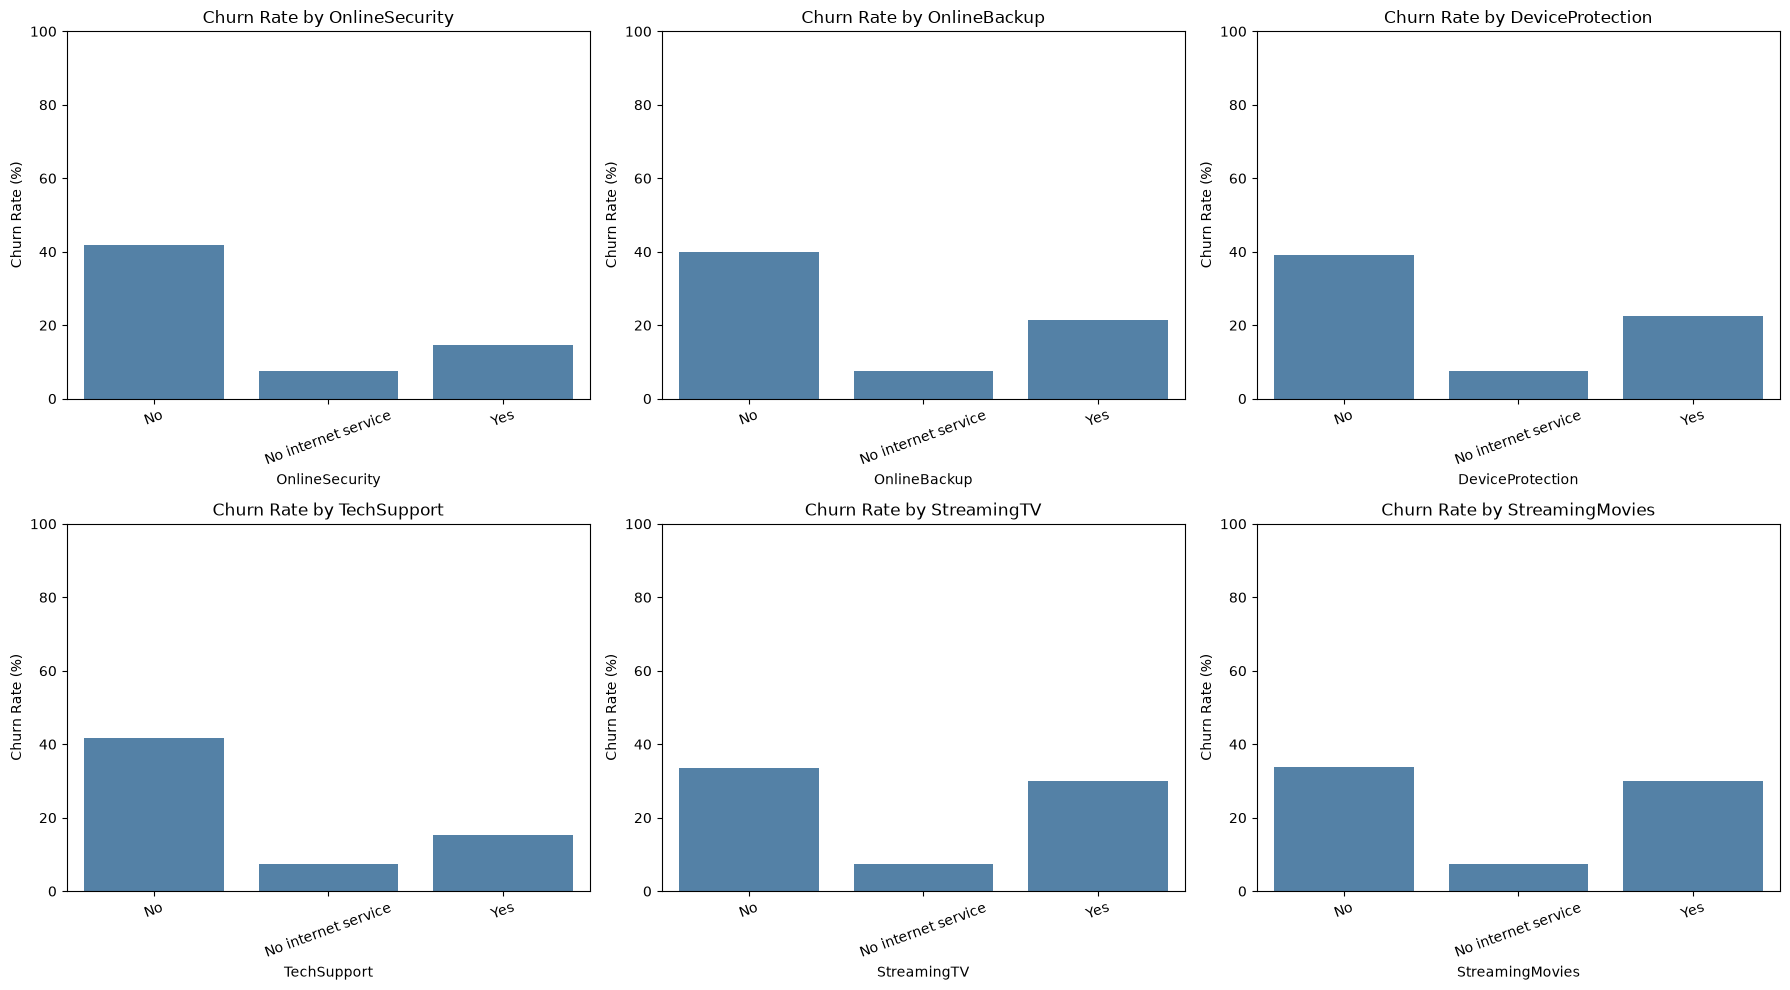

In [18]:
fig, axes = plt.subplots(
    2, 3, figsize=(18, 10)
)

for ax, feature in zip(
    axes.flatten(), service_features
):

    churn_rate = (
        df.groupby(feature)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
    )

    sns.barplot(
        x=churn_rate.index,
        y=churn_rate.values,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(f"Churn Rate by {feature}")
    ax.set_ylabel("Churn Rate (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

Create summary table

In [19]:
summary_list = []

for feature in service_features:

    summary = (
        df.groupby(feature)["Churn"]
        .agg(
            Customers="count",
            Churned=lambda x: (x == "Yes").sum()
        )
        .reset_index()
    )

    summary["ChurnRate"] = (
        summary["Churned"] /
        summary["Customers"] * 100
    )

    summary["Feature"] = feature

    summary = summary.rename(
        columns={feature: "Category"}
    )

    summary_list.append(
        summary[
            [
                "Feature",
                "Category",
                "Customers",
                "Churned",
                "ChurnRate"
            ]
        ]
    )

service_summary = pd.concat(
    summary_list,
    ignore_index=True
)

display(service_summary.round(2))

,Feature,Category,Customers,Churned,ChurnRate
0,OnlineSecurity,No,3498,1461,41.77
1,OnlineSecurity,No internet service,1526,113,7.40
2,OnlineSecurity,Yes,2019,295,14.61
3,OnlineBackup,No,3088,1233,39.93
4,OnlineBackup,No internet service,1526,113,7.40
5,OnlineBackup,Yes,2429,523,21.53
6,DeviceProtection,No,3095,1211,39.13
7,DeviceProtection,No internet service,1526,113,7.40
8,DeviceProtection,Yes,2422,545,22.50
9,TechSupport,No,3473,1446,41.64


Verify summary table

In [20]:
print("Summary Table Shape:", service_summary.shape)

print("Total Rows:", len(service_summary))

display(service_summary.head())

Summary Table Shape: (18, 5)
Total Rows: 18


,Feature,Category,Customers,Churned,ChurnRate
0,OnlineSecurity,No,3498,1461,41.766724
1,OnlineSecurity,No internet service,1526,113,7.404980
2,OnlineSecurity,Yes,2019,295,14.611194
3,OnlineBackup,No,3088,1233,39.928756
4,OnlineBackup,No internet service,1526,113,7.404980


Save CSV in  existing Report folder

In [23]:
from pathlib import Path

# Main project folder
project = Path.cwd().parent

# Existing Report folder
report_folder = project / "Report"

# Create only if missing
report_folder.mkdir(
    parents=True,
    exist_ok=True
)

# CSV location
report_file = (
    report_folder /
    "internet_services_churn_summary.csv"
)

# Save summary table
service_summary.to_csv(
    report_file,
    index=False
)

print("Report saved successfully!")
print("File exists:", report_file.exists())
print("Location:", report_file.resolve())

Report saved successfully!
File exists: True
Location: C:\Users\yashr\OneDrive\Documents\AI CUSTOMER PREDICTION CHURN\Report\internet_services_churn_summary.csv


Read your saved report

In [25]:
saved_report = pd.read_csv(report_file)

display(saved_report.head())

print("Saved report shape:", saved_report.shape)

,Feature,Category,Customers,Churned,ChurnRate
0,OnlineSecurity,No,3498,1461,41.766724
1,OnlineSecurity,No internet service,1526,113,7.404980
2,OnlineSecurity,Yes,2019,295,14.611194
3,OnlineBackup,No,3088,1233,39.928756
4,OnlineBackup,No internet service,1526,113,7.404980


Saved report shape: (18, 5)
